Seminario de Actualización · Tec. Sup. en Cs de Datos e IA · IFTS N.º 18
Docente: Cynthia M. Villagra · Ciclo lectivo 2026 · Segundo cuatrimestre

# Del dataset al modelo exportado

## El camino del entrenamiento, con regresión lineal en scikit-learn, PyTorch y Keras

Al final de este notebook vas a tener un modelo que predice el precio de una casa, guardado en un archivo que se puede usar en otra app sin volver a entrenar. En el camino vas a ver qué hace `fit` por dentro.

**Cómo se usa**

- Ejecutá las celdas **de a una**, en orden.
- **PREDICCIÓN**: escribí tu respuesta en la celda de texto **antes** de ejecutar la celda de código que sigue. No importa si no acertás.
- **ERROR INTENCIONAL**: el error es a propósito. Puede ser un mensaje de error en rojo o un resultado que no tiene sentido, sin ningún aviso. Mirá lo que aparece antes de seguir.
- Los términos nuevos aparecen en **negrita** la primera vez que se usan. Están todos juntos en el glosario del final.

## Preparar el entorno

Desde la carpeta del proyecto, activá el entorno e instalá las dependencias una sola vez:

```powershell
.\.venv\Scripts\Activate.ps1
python -m pip install -r requirements.txt
```

En Jupyter, seleccioná el kernel **Python (Camino - Entrenamiento)**. Keras usa PyTorch como backend.

In [1]:
import os

os.environ.setdefault("KERAS_BACKEND", "torch")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

np.set_printoptions(precision=3, suppress=True)

## 1. El problema

Tenemos 200 casas con su precio, en miles de US$.

In [2]:
rng = np.random.default_rng(42)
n = 200
m2 = rng.integers(35, 121, n)
balcon = rng.integers(0, 2, n)
ascensor = rng.integers(0, 2, n)
precio = 1.5 * m2 + 8 * balcon + 12 * ascensor + 20 + rng.normal(0, 4, n)

casas = pd.DataFrame({"m2": m2, "balcon": balcon, "ascensor": ascensor, "precio": precio.round(1)})
casas.head(8)

,m2,balcon,ascensor,precio
0,42,0,1,93.8
1,101,1,1,191.1
2,91,0,0,155.5
3,72,1,1,148.6
4,72,0,0,133.9
5,108,0,1,183.7
6,42,1,0,90.1
7,94,1,0,169.7


`balcon` y `ascensor` valen 1 si la casa lo tiene y 0 si no.

Llega una casa nueva: **65 m², con balcón, sin ascensor**. No tiene precio. ¿Cuánto vale?

Para responderlo necesitamos una fórmula que, a partir de los m², el balcón y el ascensor, devuelva un precio. Si suponemos que cada característica suma una cantidad fija, la fórmula tiene esta forma:

  precio = **w1** · m2 + **w2** · balcon + **w3** · ascensor + **b**

- `m2`, `balcon` y `ascensor` son las **características** (o entradas): las llamamos x1, x2, x3.
- `precio` es la **etiqueta** (o salida): la llamamos y.
- w1, w2, w3 son los **pesos**: cuánto suma cada característica.
- b es el **bias**: el precio base, cuando todas las x valen 0.

Entrenar es encontrar los números w1, w2, w3 y b que mejor reproducen los precios de la tabla.

**PREDICCIÓN 1.** Antes de entrenar nada, vamos a estimar los pesos mirando los datos. Un peso dice **cuánto cambia el precio cuando cambia una característica y las demás quedan iguales**. Los precios tienen una parte al azar, así que no va a dar exacto: buscamos un valor aproximado.

**w1: cuánto suma cada m²**

Cada punto del gráfico es una casa.

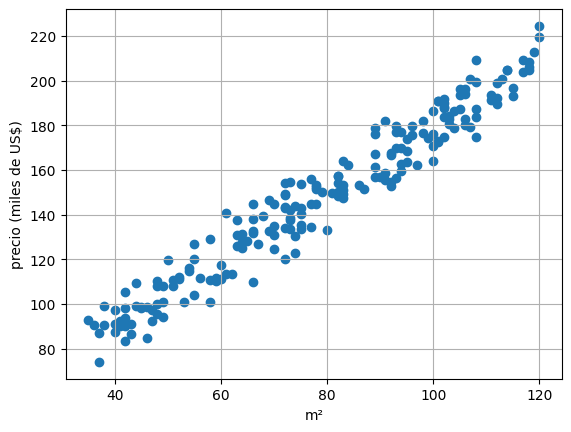

In [3]:
plt.scatter(casas["m2"], casas["precio"])
plt.xlabel("m²")
plt.ylabel("precio (miles de US$)")
plt.grid(True)
plt.show()

Mirá el gráfico: cuando los m² pasan de 50 a 100, ¿cuánto sube el precio, más o menos? Dividí esa subida por 50. Eso es lo que suma cada m², en miles de US$.

*Referencia para comparar (no la presentes como predicción previa si no la anotaste antes de ejecutar):*

- subida del precio entre 50 y 100 m²: aproximadamente 75 mil US$;
- w1 (subida / 50): aproximadamente **1,5 miles de US$ por m²**.

La estimación es aproximada porque los puntos tienen ruido.

**w2: cuánto suma tener balcón**

Para ver solo el efecto del balcón, comparamos casas parecidas en lo demás: todas tienen entre 60 y 70 m² y ninguna tiene ascensor. Lo único que cambia es el balcón.

In [4]:
parecidas = casas[casas["m2"].between(60, 70) & (casas["ascensor"] == 0)]
display(parecidas.sort_values("balcon"))
print("Promedios según balcón:")
print(parecidas.groupby("balcon")[["m2", "precio"]].mean().round(1))

,m2,balcon,ascensor,precio
52,66,0,0,109.8
153,60,0,0,111.3
162,70,0,0,124.5
166,62,0,0,113.3
135,61,1,0,113.6
64,70,1,0,130.7
143,70,1,0,134.9
43,65,1,0,128.1
163,69,1,0,132.9
187,67,1,0,127.1


Promedios según balcón:
          m2  precio
balcon              
0       64.5   114.7
1       67.0   127.9


¿Cuánto más cuestan, en promedio, las que tienen balcón?

*Referencia para comparar (no la presentes como predicción previa si no la anotaste antes de ejecutar):* w2 ≈ **8 miles de US$** (unos 8.000 US$ adicionales por tener balcón). La comparación puede variar por el ruido y por pequeñas diferencias entre las casas.

**w3: cuánto suma tener ascensor**

Lo mismo, ahora con casas de entre 60 y 70 m² sin balcón. Lo único que cambia es el ascensor.

In [5]:
parecidas = casas[casas["m2"].between(60, 70) & (casas["balcon"] == 0)]
display(parecidas.sort_values("ascensor"))
print("Promedios según ascensor:")
print(parecidas.groupby("ascensor")[["m2", "precio"]].mean().round(1))

,m2,balcon,ascensor,precio
52,66,0,0,109.8
153,60,0,0,111.3
166,62,0,0,113.3
162,70,0,0,124.5
67,66,0,1,131.9
76,63,0,1,126.0
62,66,0,1,132.5
21,66,0,1,137.9
138,64,0,1,131.2
93,68,0,1,139.2


Promedios según ascensor:
            m2  precio
ascensor              
0         64.5   114.7
1         64.9   131.3


¿Cuánto más cuestan, en promedio, las que tienen ascensor?

*Referencia para comparar (no la presentes como predicción previa si no la anotaste antes de ejecutar):* w3 ≈ **12 miles de US$** (unos 12.000 US$ adicionales por tener ascensor). La estimación puede variar por el ruido.

## 2. Una vuelta del camino, a mano

Antes de usar cualquier librería, vamos a hacer **una** vuelta del entrenamiento con los números a la vista. Este es el camino que vamos a recorrer:

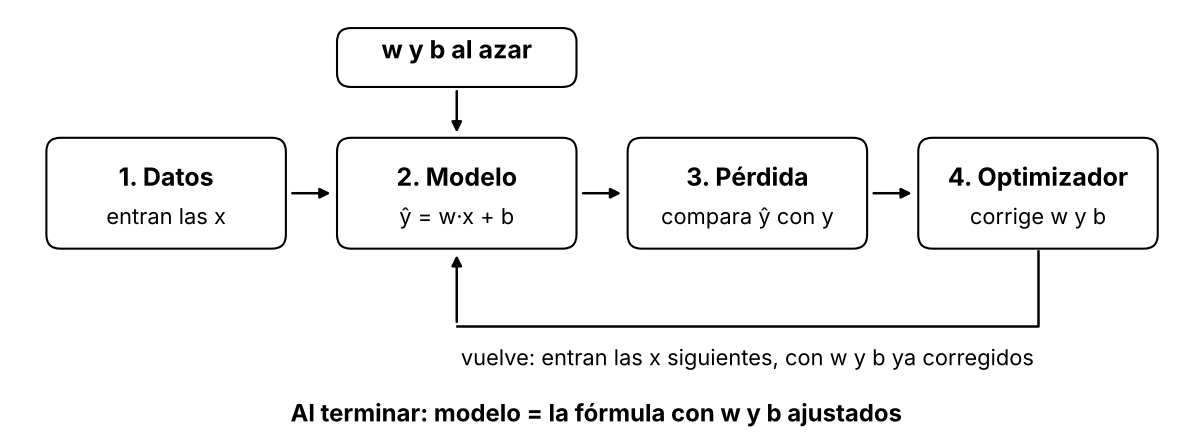

### Inicio: w y b al azar

El entrenamiento arranca sin saber nada: los pesos se eligen al azar y el bias empieza en 0.

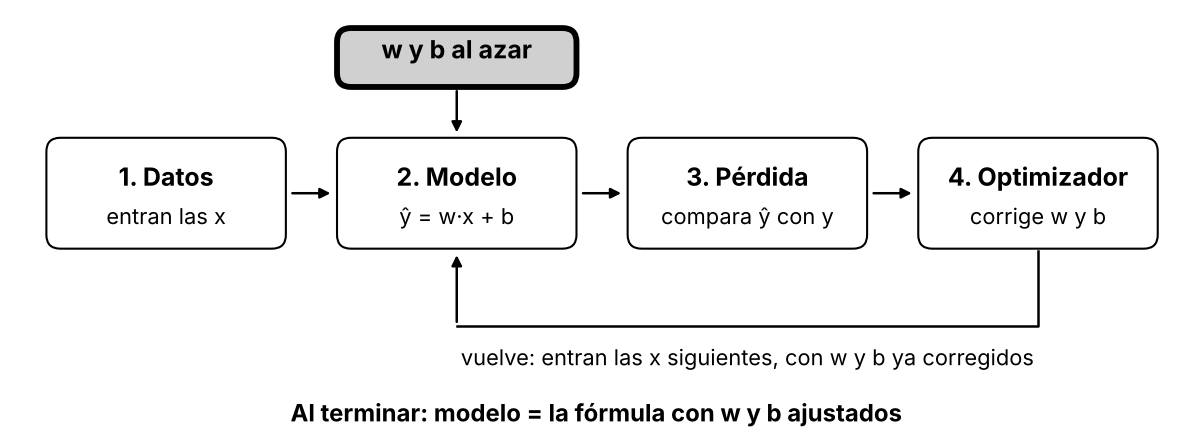

In [6]:
rng_mano = np.random.default_rng(1)
w = rng_mano.normal(0, 1, 3)
b = 0.0
print("w =", w)
print("b =", b)

w = [0.346 0.822 0.33 ]
b = 0.0


### Caja 1: entran los datos

Tomamos la primera casa de la tabla.

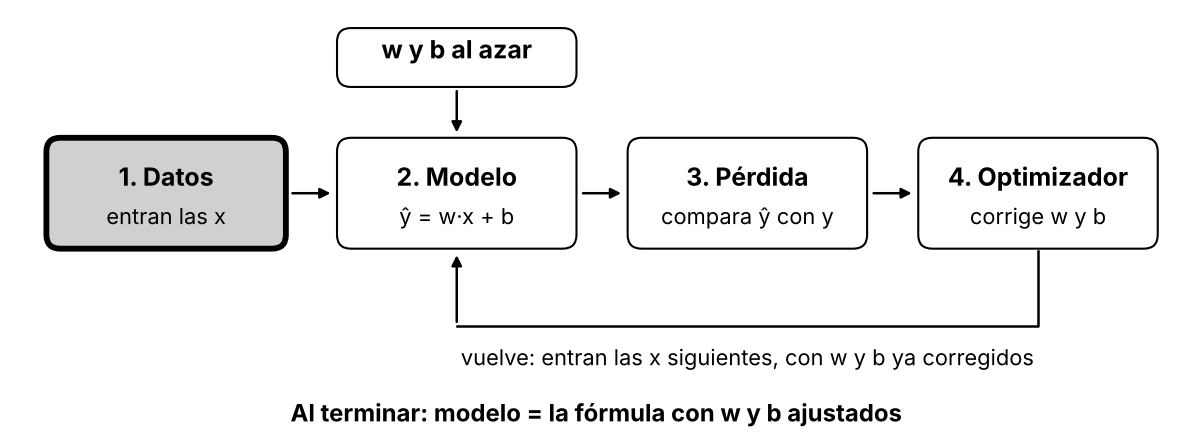

In [7]:
x = casas[["m2", "balcon", "ascensor"]].iloc[0].values
y = casas["precio"].iloc[0]
print("x =", x)
print("y =", y)

x = [42  0  1]
y = 93.8


### Caja 2: el modelo predice

La predicción se escribe **ŷ** ("y sombrero") para no confundirla con el precio real y.

**PREDICCIÓN 2.** Con esos pesos al azar, ¿la predicción va a estar cerca del precio real o lejos? ¿Por qué?

**Reflexión después de ejecutar:** La predicción quedó lejos del precio real: dio 14,84 frente a 93,8 (miles de US$). Los pesos se habían elegido al azar y todavía no aprendieron la relación entre las características y el precio. Si había anotado una predicción antes de ejecutar, la comparo con este resultado.

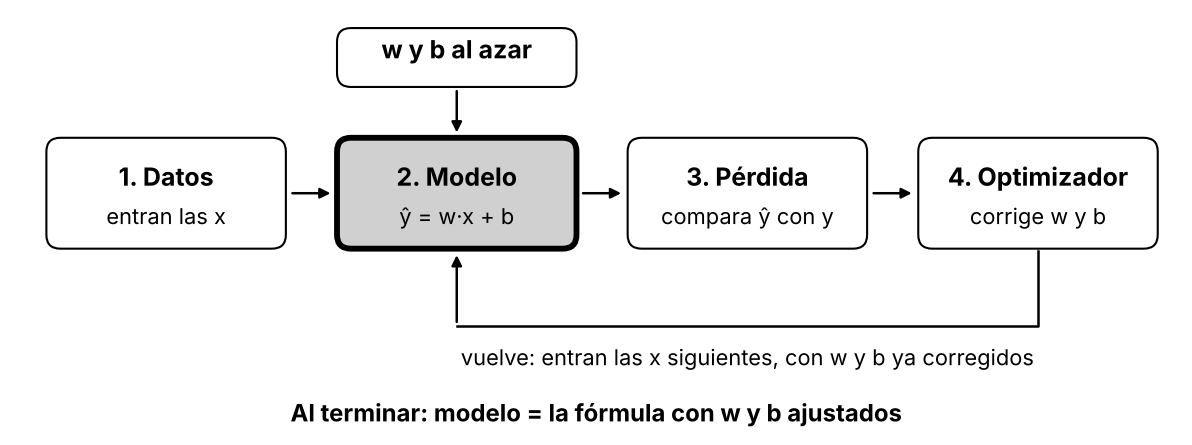

In [8]:
y_pred = w[0] * x[0] + w[1] * x[1] + w[2] * x[2] + b
print("ŷ =", round(y_pred, 2))
print("y =", y)

ŷ = 14.84
y = 93.8


### Caja 3: la pérdida mide cuánto se equivocó

La **pérdida** (loss) es un número que mide el error. Acá usamos el error al cuadrado: siempre da positivo, y castiga más los errores grandes.

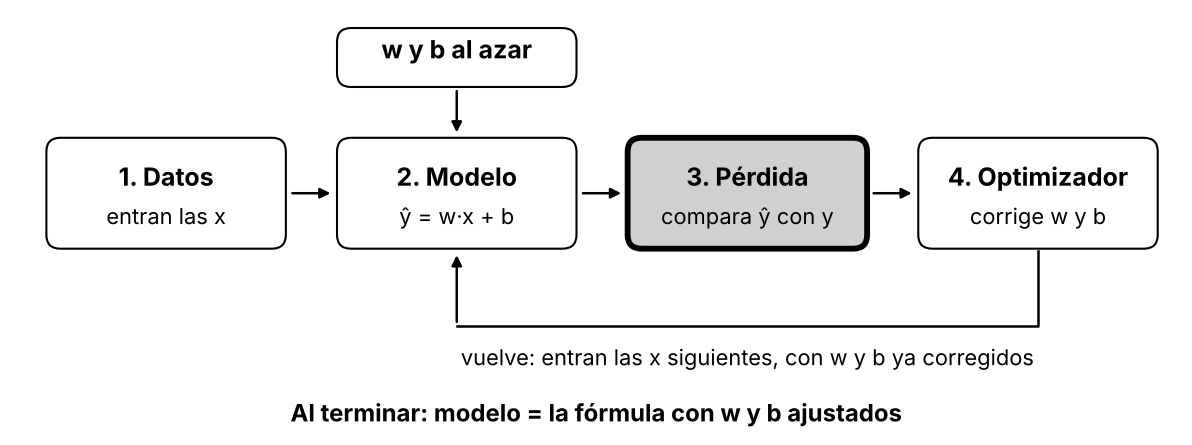

In [9]:
error = y_pred - y
perdida = error ** 2
print("error   = ŷ - y  =", round(error, 2))
print("pérdida = error² =", round(perdida, 2))

error   = ŷ - y  = -78.96
pérdida = error² = 6233.9


### Caja 4: el optimizador corrige w y b

El **optimizador** se pregunta, para cada parámetro: *si lo muevo un poquito, ¿el error sube o baja, y cuánto?* La respuesta es el **gradiente**. Para esta fórmula:

- gradiente de cada peso: 2 · error · x
- gradiente del bias: 2 · error

Después corrige cada parámetro en sentido contrario al gradiente:

  **parámetro = parámetro − tasa × gradiente**

La **tasa de aprendizaje** dice qué tan grande es el paso. No la aprende el algoritmo: la elegís vos. Por eso es un **hiperparámetro**. En cambio, w y b son **parámetros**: los aprende el algoritmo.

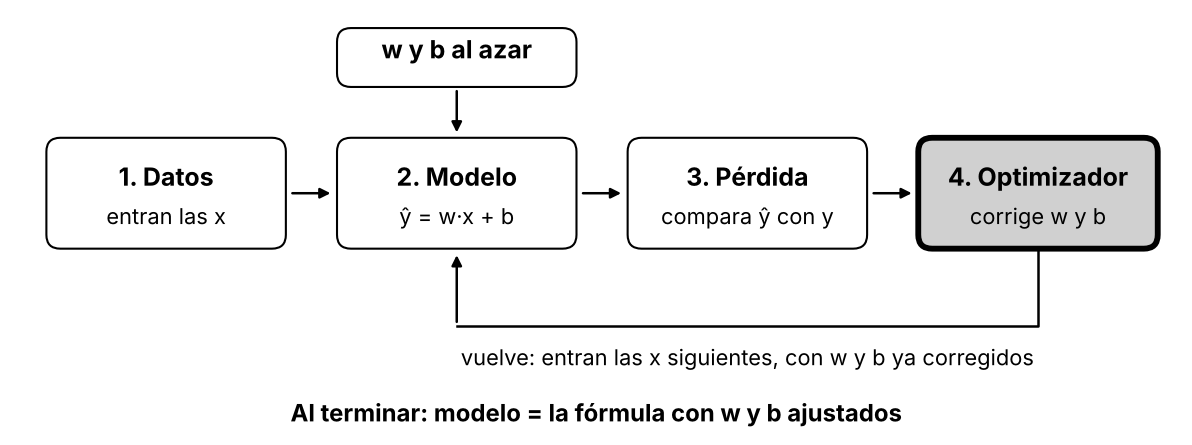

In [10]:
grad_w = 2 * error * x
grad_b = 2 * error
print("gradiente de w =", grad_w)
print("gradiente de b =", round(grad_b, 2))

gradiente de w = [-6632.222    -0.     -157.91 ]
gradiente de b = -157.91


Mirá los signos: si el gradiente es negativo, la corrección **sube** ese parámetro. Y el de `m2` es mucho más grande que los otros porque `m2` vale mucho más que 0 o 1.

In [11]:
tasa = 0.0001     # hiperparámetro

w = w - tasa * grad_w
b = b - tasa * grad_b
print("w corregido =", w)
print("b corregido =", round(b, 4))

w corregido = [1.009 0.822 0.346]
b corregido = 0.0158


### La vuelta: ¿mejoró?

Con los parámetros corregidos, la misma casa:

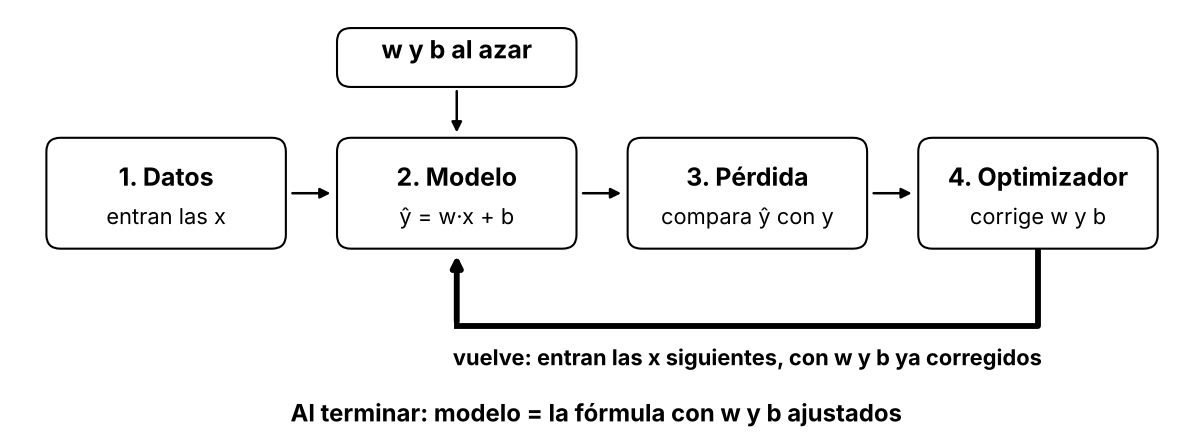

In [12]:
y_pred_nueva = w[0] * x[0] + w[1] * x[1] + w[2] * x[2] + b
print("antes:   ŷ =", round(y_pred, 2), "  pérdida =", round(perdida, 2))
print("después: ŷ =", round(y_pred_nueva, 2), "  pérdida =", round((y_pred_nueva - y) ** 2, 2))

antes:   ŷ = 14.84   pérdida = 6233.9
después: ŷ = 42.73   pérdida = 2607.95


Una sola corrección ya bajó el error para esa casa.

### ¿Y después? Filas, vueltas y épocas

La vuelta **no se repite sobre la misma fila**. Si siguiéramos corrigiendo con la primera casa, los parámetros terminarían sirviendo solo para esa casa. Lo que sigue es:

1. Entra la **segunda** casa, con los w y b que dejó la primera. Predice, mide, corrige.
2. Entra la tercera, con los w y b que dejó la segunda. Y así hasta la última.
3. Cuando pasaron **todas** las filas una vez, terminó una **época**.
4. Empieza la época siguiente: vuelve a entrar la primera casa, pero ahora con los w y b que dejó la última.

Más adelante vamos a entrenar con 160 de las 200 casas (en la sección 3 se ve por qué). Con 160 casas y 50 épocas, cada casa entra 50 veces y w y b se corrigen 160 × 50 = 8000 veces. La cantidad de épocas no la aprende el algoritmo: la elegís vos, así que es otro **hiperparámetro**.

Hay tres formas de hacer entrar las filas, y en este notebook vas a ver dos:

| Forma | Qué entra en cada vuelta | Correcciones por época | Dónde la vas a ver |
|---|---|---|---|
| Fila por fila | 1 fila | 160 (una por fila) | `SGDRegressor` |
| Todas juntas | las 160 filas; se promedia la pérdida | 1 | PyTorch y Keras, en este notebook |
| De a lotes | un grupo de filas, por ejemplo 32 | 160 / 32 = 5 | lo más común en redes neuronales |

En las tres, el camino es el mismo: lo único que cambia es cuántas filas entran antes de cada corrección. Ese número se llama **tamaño de lote** (batch size), y también es un hiperparámetro.

Hacerlo a mano para 160 casas y cientos de épocas no tiene sentido: para eso están las librerías.

## 3. scikit-learn

Primero separamos los datos. El modelo se entrena con una parte (**train**) y se evalúa con otra que no vio (**test**), para saber si anda bien con casas nuevas.

In [13]:
from sklearn.model_selection import train_test_split

X = casas[["m2", "balcon", "ascensor"]]
y = casas["precio"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=0)

print("train:", len(X_train), "casas")
print("test: ", len(X_test), "casas")

train: 160 casas
test:  40 casas


### 3.1 `LinearRegression`

`fit` recibe las x y las y de entrenamiento y ajusta los parámetros.

Documentación oficial: [sklearn.linear_model.LinearRegression](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LinearRegression.html)

In [14]:
from sklearn.linear_model import LinearRegression

lineal = LinearRegression()
lineal.fit(X_train, y_train)

LinearRegression()

In [15]:
print("w =", lineal.coef_)
print("b =", round(lineal.intercept_, 2))

w = [ 1.503  8.625 12.565]
b = 19.27


Compará con tu PREDICCIÓN 1.

Todo lo que `fit` aprende termina con guion bajo: `coef_` son los pesos, `intercept_` es el bias.

Un detalle: `LinearRegression` **no** recorre el camino. Para este modelo existe una fórmula matemática que calcula los mejores w y b de una sola vez (mínimos cuadrados). Para ver el camino, scikit-learn tiene otro algoritmo.

### 3.2 `SGDRegressor`: el mismo modelo, recorriendo el camino

`SGDRegressor` hace lo mismo que hicimos a mano, **fila por fila**: entra una casa, predice, mide la pérdida y corrige; entra la siguiente con los parámetros corregidos, y así. Al terminar cada época, mezcla el orden de las filas y empieza otra vez. `eta0` es la tasa de aprendizaje.

Documentación oficial: [sklearn.linear_model.SGDRegressor](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.SGDRegressor.html)

**PREDICCIÓN 3.** ¿Va a llegar a los mismos w y b que `LinearRegression`?

**Reflexión después de ejecutar:** SGD puede acercarse a `LinearRegression` si converge, porque ambos ajustan la misma fórmula. En esta ejecución, sin escalar las entradas, los pesos y la predicción crecieron a valores enormes; con las entradas escaladas sí se acercan. Si había anotado una predicción antes de ejecutar, la comparo con este resultado.

**ERROR INTENCIONAL**

In [16]:
from sklearn.linear_model import SGDRegressor

sgd = SGDRegressor(eta0=0.01, learning_rate="constant", penalty=None, random_state=0)
sgd.fit(X_train, y_train)



SGDRegressor(learning_rate='constant', penalty=None, random_state=0)

In [17]:
print("w =", sgd.coef_)
print("b =", sgd.intercept_)
print("casa nueva:", sgd.predict(pd.DataFrame({"m2": [65], "balcon": [1], "ascensor": [0]})))

w = [-6.589e+11  3.680e+10  1.198e+10]
b = [2.115e+10]
casa nueva: [-4.277e+13]


No apareció ningún mensaje de error: `fit` terminó como si todo hubiera salido bien. Pero mirá los pesos y el precio de la casa nueva, y comparalos con los de `LinearRegression` en la sección 3.1. ¿Tienen sentido? (`e+11` significa "por 10 elevado a la 11": `-6.589e+11` es −658.900.000.000.)



Pasó lo que se veía en la vuelta a mano: el gradiente de `m2` es enorme porque `m2` vale cerca de 100, mientras que `balcon` vale 0 o 1. Con esta tasa, cada corrección se pasa de largo y los pesos saltan de un valor gigante a otro. scikit-learn no avisa: entrega pesos sin sentido como si fueran un resultado válido.

### 3.3 La transformación: escalar las x

La solución es poner todas las x en la misma escala antes de que entren al modelo. Eso es una **transformación**.

`StandardScaler` resta el promedio de cada columna y divide por su desvío. Después de escalar, todas las columnas quedan con promedio 0 y desvío 1.

El scaler **también tiene `fit`**: lo que aprende es el promedio y el desvío de cada columna. Se ajusta solo con train.

Documentación oficial: [sklearn.preprocessing.StandardScaler](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.StandardScaler.html)

In [18]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
scaler.fit(X_train)

print("promedio aprendido:", scaler.mean_)
print("desvío aprendido:  ", scaler.scale_)

promedio aprendido: [76.237  0.463  0.494]
desvío aprendido:   [23.274  0.499  0.5  ]


In [19]:
X_train_esc = scaler.transform(X_train)
X_test_esc = scaler.transform(X_test)

print("primera casa, original:", X_train.iloc[0].values)
print("primera casa, escalada:", X_train_esc[0])

primera casa, original: [103   0   1]
primera casa, escalada: [ 1.15  -0.928  1.013]


Ahora sí, `SGDRegressor` con las x escaladas. Lo entrenamos de a una época con `partial_fit` para ver cómo baja la pérdida.

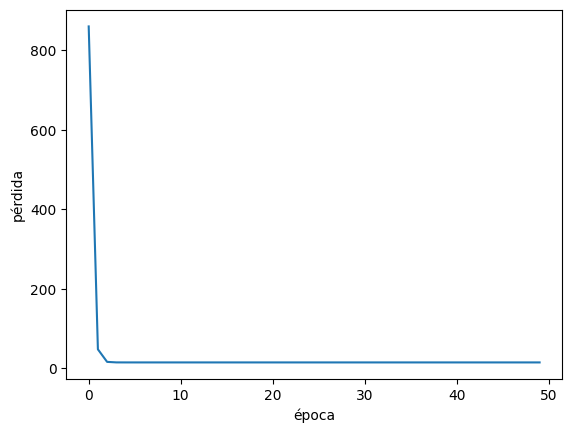

In [20]:
from sklearn.metrics import mean_squared_error

sgd = SGDRegressor(eta0=0.01, learning_rate="constant", penalty=None, random_state=0)
perdidas_sgd = []
for epoca in range(50):
    sgd.partial_fit(X_train_esc, y_train)
    perdidas_sgd.append(mean_squared_error(y_train, sgd.predict(X_train_esc)))

plt.plot(perdidas_sgd)
plt.xlabel("época"); plt.ylabel("pérdida")
plt.show()

Para comparar con `LinearRegression` hay que darle las mismas x escaladas: al cambiar la escala de las x, cambian los pesos (un peso por "desvío de m²" no es lo mismo que un peso por m²).

In [21]:
lineal_esc = LinearRegression().fit(X_train_esc, y_train)

print("LinearRegression  w =", lineal_esc.coef_, "  b =", round(lineal_esc.intercept_, 2))
print("SGDRegressor      w =", sgd.coef_, "  b =", round(sgd.intercept_[0], 2))

LinearRegression  w = [34.989  4.301  6.282]   b = 144.08
SGDRegressor      w = [34.946  4.076  6.316]   b = 144.04


Respuesta a la PREDICCIÓN 3: llegan a valores muy parecidos por dos caminos distintos. Uno con una fórmula de una vez, el otro corrigiendo de a poco.

## 4. PyTorch: el camino escrito por vos

En PyTorch no hay `fit`: el ciclo de entrenamiento se escribe a mano. Cada línea corresponde a una caja del diagrama.

| Caja | PyTorch |
|---|---|
| w y b al azar | `nn.Linear(3, 1)` |
| 2. Modelo | `y_pred = modelo_pt(X)` |
| 3. Pérdida | `perdida = criterio(y_pred, y)` |
| 4. Optimizador | `perdida.backward()` calcula el gradiente, `optimizador.step()` corrige |
| vuelve | el `for` |

### Primero: convertir los datos a tensores

Hasta acá los datos estuvieron en una tabla de pandas (`X_train`) o en un array de NumPy (`X_train_esc`). PyTorch no trabaja con ninguno de los dos: solo opera con su propio tipo de dato, el **tensor**.

Un tensor es, como un array de NumPy, una grilla de números: un número suelto, una lista, una tabla o más dimensiones. La diferencia es que el tensor puede hacer dos cosas que el array no:

- **Calcular el gradiente solo.** Mientras el modelo hace sus cuentas, PyTorch registra cada operación. Después, `backward()` recorre ese registro hacia atrás y calcula el gradiente de cada parámetro. Es lo que en la vuelta a mano hicimos con `grad_w = 2 * error * x`, pero automático y para cualquier fórmula.
- **Pasar a la placa de video (GPU)** para hacer las cuentas mucho más rápido. Acá no lo necesitamos.

Por eso, antes de entrenar, hay que convertir los datos.

Documentación oficial: [torch.Tensor](https://pytorch.org/docs/stable/tensors.html)

In [22]:
import torch
from torch import nn

Xt = torch.tensor(X_train_esc, dtype=torch.float32)
print(type(X_train_esc), X_train_esc.dtype, X_train_esc.shape)
print(type(Xt), Xt.dtype, Xt.shape)

<class 'numpy.ndarray'> float64 (160, 3)
<class 'torch.Tensor'> torch.float32 torch.Size([160, 3])


Las 160 casas con sus 3 características, ahora como tensor. Dos detalles de la conversión:

- `dtype=torch.float32`: NumPy guarda los decimales en `float64` y PyTorch crea sus pesos en `float32`. Si los datos y los pesos son de tipos distintos, PyTorch no hace la cuenta y da error. Por eso convertimos los datos al tipo de los pesos.

In [23]:
yt = torch.tensor(y_train.values, dtype=torch.float32).reshape(-1, 1)
print("y como lista:  ", torch.tensor(y_train.values).shape)
print("y como columna:", yt.shape)

y como lista:   torch.Size([160])
y como columna: torch.Size([160, 1])


- `reshape(-1, 1)`: el modelo devuelve una predicción por fila **en forma de columna**, (160, 1). Las y tienen que tener la misma forma para que la pérdida compare cada ŷ con su y. `-1` significa "calculá vos cuántas filas son".

### Inicio: w y b al azar

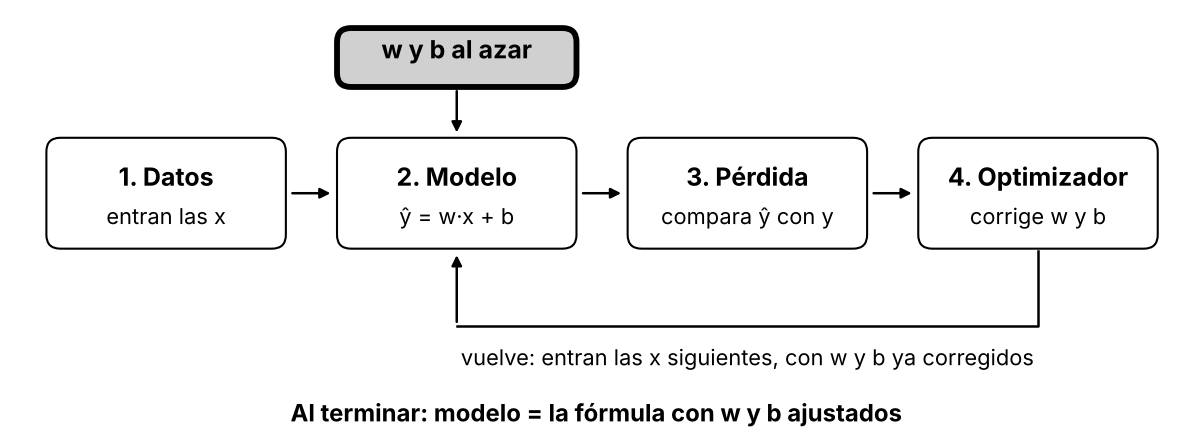

In [24]:
torch.manual_seed(0)
modelo_pt = nn.Linear(3, 1)

print("w =", modelo_pt.weight.data)
print("b =", modelo_pt.bias.data)

w = tensor([[-0.0043,  0.3097, -0.4752]])
b = tensor([-0.4249])


`nn.Linear(3, 1)` es exactamente ŷ = w1·x1 + w2·x2 + w3·x3 + b: 3 entradas, 1 salida.

Definimos la pérdida y el optimizador. `MSELoss` es el promedio de los errores al cuadrado de todas las filas (**MSE**, error cuadrático medio). `lr` es la tasa de aprendizaje.

Documentación oficial: [torch.nn.Linear](https://pytorch.org/docs/stable/generated/torch.nn.Linear.html) · [torch.nn.MSELoss](https://pytorch.org/docs/stable/generated/torch.nn.MSELoss.html) · [torch.optim.SGD](https://pytorch.org/docs/stable/generated/torch.optim.SGD.html)

In [25]:
criterio = nn.MSELoss()
optimizador = torch.optim.SGD(modelo_pt.parameters(), lr=0.1)

### Una vuelta, caja por caja

En PyTorch vamos a usar la forma **todas juntas**: en cada vuelta entran las 160 casas a la vez, la pérdida es el promedio de los 160 errores y se hace una sola corrección. Así, cada vuelta es una época.

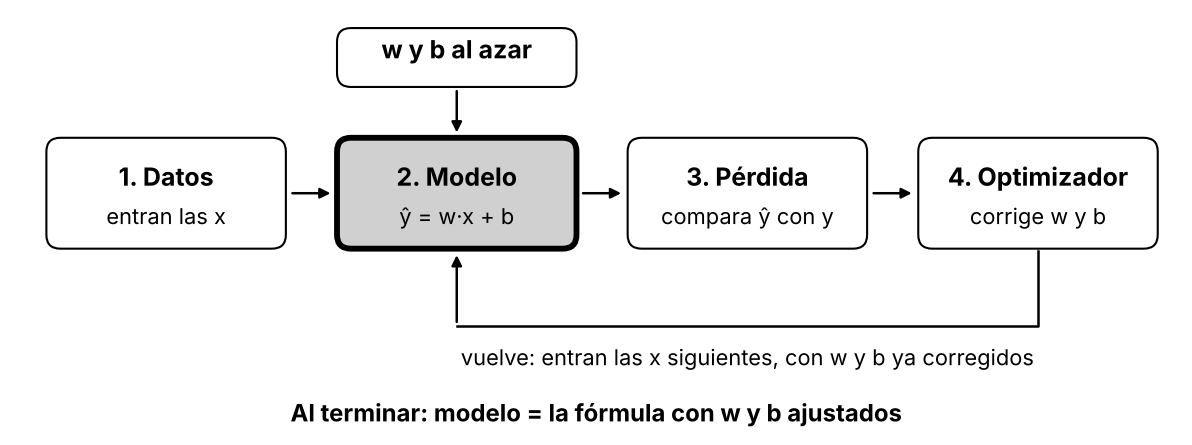

In [26]:
y_pred = modelo_pt(Xt)
print("primeras 3 predicciones:", y_pred[:3].detach().ravel())
print("primeros 3 precios:     ", yt[:3].ravel())

primeras 3 predicciones: tensor([-1.1983, -0.2496, -0.5708])
primeros 3 precios:      tensor([184.1000, 192.3000, 146.8000])


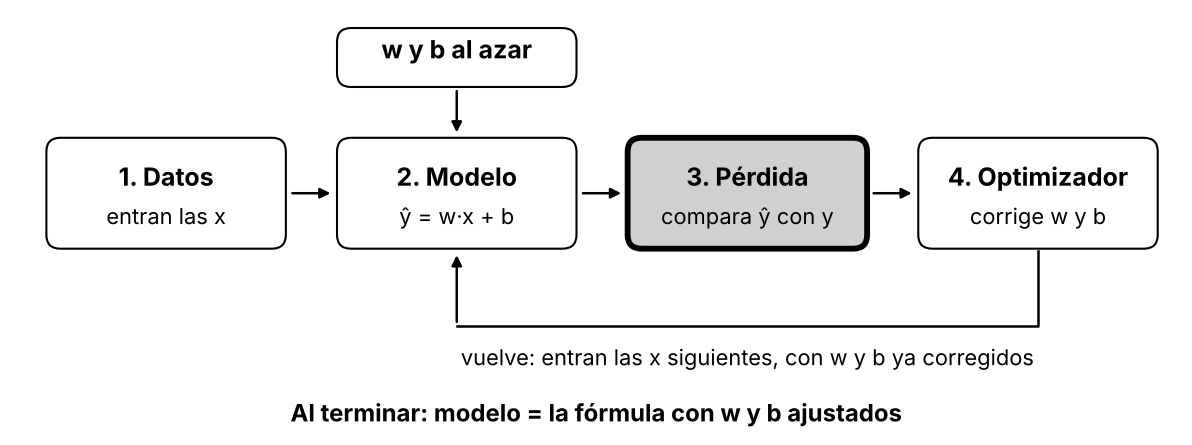

In [27]:
perdida = criterio(y_pred, yt)
print("pérdida =", perdida.item())

pérdida = 22152.091796875


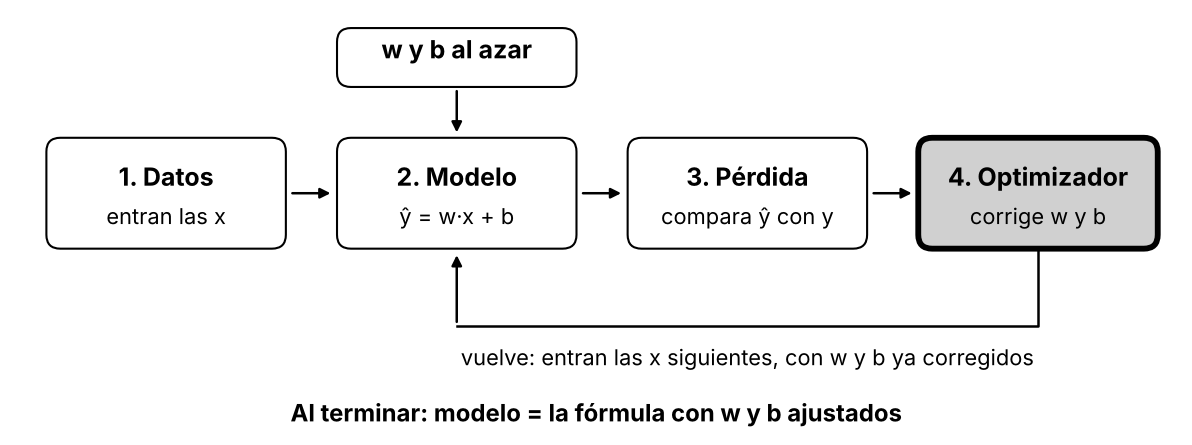

In [28]:
optimizador.zero_grad()      # borra el gradiente anterior
perdida.backward()           # calcula el gradiente
print("gradiente de w =", modelo_pt.weight.grad)
print("gradiente de b =", modelo_pt.bias.grad)

gradiente de w = tensor([[-69.2402,  -5.8190,  -9.5076]])
gradiente de b = tensor([-289.0098])


In [29]:
optimizador.step()           # corrige w y b
print("w corregido =", modelo_pt.weight.data)
print("b corregido =", modelo_pt.bias.data)

w corregido = tensor([[6.9197, 0.8916, 0.4756]])
b corregido = tensor([28.4761])


### Ahora, muchas vueltas

Las mismas líneas, dentro de un `for`. Como cada vuelta usa las 160 casas, `range(200)` son 200 épocas y 200 correcciones.

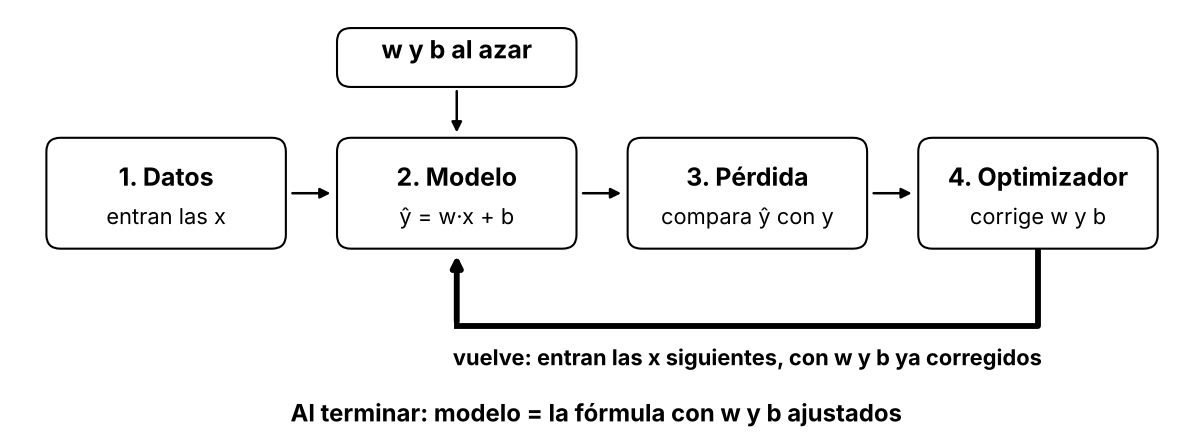

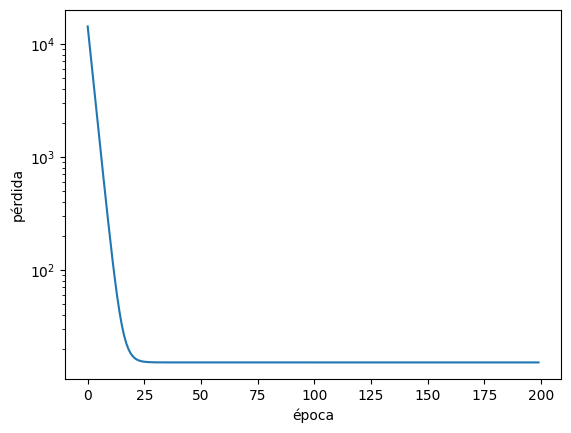

In [30]:
perdidas_pt = []
for epoca in range(200):
    y_pred = modelo_pt(Xt)                 # 2. modelo
    perdida = criterio(y_pred, yt)         # 3. pérdida
    optimizador.zero_grad()
    perdida.backward()                     # 4. gradiente
    optimizador.step()                     # 4. corrección
    perdidas_pt.append(perdida.item())

plt.plot(perdidas_pt)
plt.xlabel("época"); plt.ylabel("pérdida"); plt.yscale("log")
plt.show()

In [31]:
print("PyTorch           w =", modelo_pt.weight.data.ravel(), "  b =", round(modelo_pt.bias.item(), 2))
print("LinearRegression  w =", lineal_esc.coef_, "  b =", round(lineal_esc.intercept_, 2))

PyTorch           w = tensor([34.9893,  4.3006,  6.2822])   b = 144.08
LinearRegression  w = [34.989  4.301  6.282]   b = 144.08


**PREDICCIÓN 4.** Si la tasa de aprendizaje pasa de 0.1 a 1.5, el paso de cada corrección es 15 veces más grande. ¿El modelo aprende más rápido, igual o peor?

**Reflexión después de ejecutar:** Con la tasa de aprendizaje más alta, el modelo empeoró: el paso se pasó del mínimo y la pérdida creció en cada época, de aproximadamente 22.152 a 365.461.696. Si había anotado una predicción antes de ejecutar, la comparo con este resultado.

In [32]:
torch.manual_seed(0)
modelo_rapido = nn.Linear(3, 1)
optimizador_rapido = torch.optim.SGD(modelo_rapido.parameters(), lr=1.5)

for epoca in range(8):
    perdida = criterio(modelo_rapido(Xt), yt)
    optimizador_rapido.zero_grad()
    perdida.backward()
    optimizador_rapido.step()
    print(f"época {epoca}   pérdida {perdida.item():,.0f}")

época 0   pérdida 22,152
época 1   pérdida 88,299
época 2   pérdida 352,713
época 3   pérdida 1,411,002
época 4   pérdida 5,651,341
época 5   pérdida 22,659,024
época 6   pérdida 90,947,912
época 7   pérdida 365,461,696


Con un paso demasiado grande, cada corrección se pasa del mínimo y cae más lejos del otro lado. La pérdida no baja: crece. Elegir los hiperparámetros también es parte del trabajo.

## 5. Keras: el mismo ciclo, adentro de `fit`

Keras vuelve a tener `fit`. Ahora sabés qué hace por dentro: el mismo `for` de PyTorch. Vos le decís qué pérdida, qué optimizador y cuántas épocas, y Keras arma el ciclo.

**Dense** es el nombre de Keras para la misma capa lineal: ŷ = w·x + b.

A diferencia de PyTorch, a Keras le podés pasar directamente los arrays de NumPy: la conversión a tensores la hace `fit` por dentro.

Documentación oficial: [keras.layers.Dense](https://keras.io/api/layers/core_layers/dense/) · [Model.fit](https://keras.io/api/models/model_training_apis/)

In [33]:
import keras

keras.utils.set_random_seed(0)
modelo_k = keras.Sequential([keras.Input(shape=(3,)), keras.layers.Dense(1)])

w_k, b_k = modelo_k.layers[0].get_weights()
print("w al azar =", w_k.ravel())
print("b al azar =", b_k)

w al azar = [-0.359  0.975 -0.788]
b al azar = [0.]


In [34]:
modelo_k.compile(optimizer=keras.optimizers.SGD(learning_rate=0.1), loss="mse")

**PREDICCIÓN 5.** En PyTorch, el ciclo ocupó un `for` con cinco líneas. ¿Cuántas líneas va a ocupar en Keras?

**Reflexión después de ejecutar:** En Keras alcanza con una llamada a `modelo_k.fit(...)`; esa función oculta el ciclo de entrenamiento que en PyTorch escribimos dentro de un `for`. Si había anotado una predicción antes de ejecutar, la comparo con este resultado.

In [35]:
historia = modelo_k.fit(X_train_esc, y_train.values, epochs=200, batch_size=len(X_train_esc), verbose=0)

`epochs=200` es la cantidad de épocas. `batch_size` es el tamaño de lote: cuántas filas entran antes de cada corrección. Con `batch_size=len(X_train_esc)` entran las 160 juntas, igual que en PyTorch. Si no lo indicás, Keras usa lotes de 32 filas.

`fit` de Keras devuelve el historial de la pérdida. Los parámetros quedan guardados adentro del modelo.

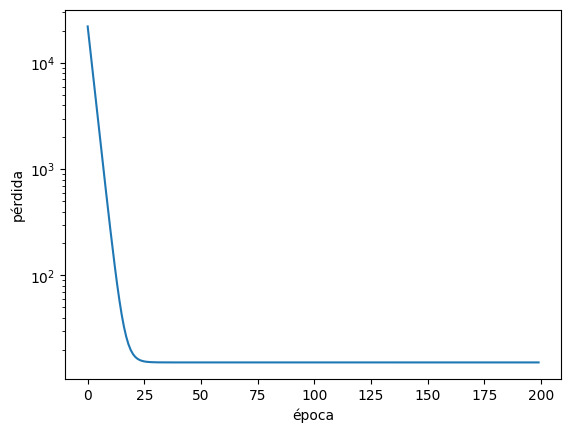

Keras             w = [34.989  4.301  6.282]   b = 144.08
LinearRegression  w = [34.989  4.301  6.282]   b = 144.08


In [36]:
plt.plot(historia.history["loss"])
plt.xlabel("época"); plt.ylabel("pérdida"); plt.yscale("log")
plt.show()

w_k, b_k = modelo_k.layers[0].get_weights()
print("Keras             w =", w_k.ravel(), "  b =", round(float(b_k[0]), 2))
print("LinearRegression  w =", lineal_esc.coef_, "  b =", round(lineal_esc.intercept_, 2))

## 6. ¿Anda bien? Evaluar con casas que no vio

Ahora usamos test: las 40 casas que ningún modelo vio al entrenar. Dos medidas:

- **RMSE**: cuánto se equivoca en promedio, en miles de US$ (es la raíz del MSE).
- **R²**: qué parte de las diferencias de precio entre casas explica el modelo. 1 es perfecto; 0 es lo mismo que decir siempre el precio promedio.

In [37]:
from sklearn.metrics import r2_score

predicciones = {
    "LinearRegression": lineal_esc.predict(X_test_esc),
    "SGDRegressor": sgd.predict(X_test_esc),
    "PyTorch": modelo_pt(torch.tensor(X_test_esc, dtype=torch.float32)).detach().numpy().ravel(),
    "Keras": modelo_k.predict(X_test_esc, verbose=0).ravel(),
}
for nombre, p in predicciones.items():
    rmse = mean_squared_error(y_test, p) ** 0.5
    print(f"{nombre:17}  RMSE = {rmse:5.2f} miles de US$   R² = {r2_score(y_test, p):.3f}")

LinearRegression   RMSE =  4.42 miles de US$   R² = 0.982
SGDRegressor       RMSE =  4.38 miles de US$   R² = 0.982
PyTorch            RMSE =  4.42 miles de US$   R² = 0.982
Keras              RMSE =  4.42 miles de US$   R² = 0.982


Los cuatro dan prácticamente lo mismo: son la misma fórmula con casi los mismos parámetros.

El dataset se generó con estos valores, más un poco de ruido al azar que ningún modelo puede predecir:

| | w1 (m²) | w2 (balcón) | w3 (ascensor) | b |
|---|---|---|---|---|
| Valores con que se generó | 1.5 | 8 | 12 | 20 |

Compará con lo que encontró `LinearRegression` en la sección 3.1 y con tu PREDICCIÓN 1.

Si tu estimación del balcón o del ascensor dio más alta que el valor real, hay dos motivos:

- **Los m².** Mirá los promedios de m² de la tabla del balcón: las casas con balcón eran, en promedio, 2,5 m² más grandes. Parte de la diferencia de precio venía de esos m², no del balcón.
- **El azar.** En la tabla del ascensor los m² son casi iguales, y aun así la diferencia dio más que 12. Son pocas casas, y cada precio tiene su parte al azar: con tan pocas filas, el promedio se corre bastante.

Separar a mano el efecto de cada característica es difícil; la regresión lineal lo hace con todas a la vez y usando todas las casas de train.

## 7. Entonces, ¿qué es un modelo?

Un **modelo** es la fórmula con los parámetros ya ajustados. Recibe x y devuelve ŷ.

Con los w y b que encontró `LinearRegression`, el precio de la casa nueva del principio se puede calcular a mano:

In [38]:
w, b = lineal.coef_, lineal.intercept_
casa_nueva = pd.DataFrame({"m2": [65], "balcon": [1], "ascensor": [0]})

a_mano = w[0] * 65 + w[1] * 1 + w[2] * 0 + b
print(f"a mano:  {w[0]:.2f}·65 + {w[1]:.2f}·1 + {w[2]:.2f}·0 + {b:.2f} = {a_mano:.1f}")
print(f"predict: {lineal.predict(casa_nueva)[0]:.1f}")

a mano:  1.50·65 + 8.63·1 + 12.57·0 + 19.27 = 125.6
predict: 125.6


Pero los modelos que recorrieron el camino aprendieron con x **escaladas**. Para usarlos, la casa nueva tiene que pasar primero por el mismo scaler. Por eso, el modelo completo es: **transformación + fórmula con sus parámetros**.

En scikit-learn eso se arma con un **Pipeline**: el scaler y el regresor quedan encadenados, y `predict` recibe las x originales.

In [39]:
from sklearn.pipeline import make_pipeline

pipeline = make_pipeline(StandardScaler(), LinearRegression())
pipeline.fit(X_train, y_train)
print("casa nueva:", pipeline.predict(casa_nueva)[0].round(1), "miles de US$")

casa nueva: 125.6 miles de US$


## 8. Exportar el modelo

**Exportar** es guardar el modelo en un archivo para usarlo en otro lado (una app de Gradio, un Space de Hugging Face) sin volver a entrenar.

En clase exportamos uno por librería. Los demás formatos los investigan en la Actividad del final.

In [40]:
from pathlib import Path
CARPETA = Path("modelos_exportados")
CARPETA.mkdir(exist_ok=True)

### 8.1 scikit-learn: joblib

In [41]:
import joblib

joblib.dump(pipeline, CARPETA / "casas.joblib")

['modelos_exportados/casas.joblib']

Hacemos de cuenta que somos otra persona que solo tiene el archivo:

In [42]:
modelo_cargado = joblib.load(CARPETA / "casas.joblib")
print("casa nueva:", modelo_cargado.predict(casa_nueva)[0].round(1))

casa nueva: 125.6


¿Qué hay adentro? El Pipeline completo, con los parámetros de sus dos pasos:

In [43]:
scaler_cargado, regresor_cargado = modelo_cargado[0], modelo_cargado[1]
print("scaler:   promedio =", scaler_cargado.mean_, "  desvío =", scaler_cargado.scale_)
print("regresor: w =", regresor_cargado.coef_, "  b =", round(regresor_cargado.intercept_, 2))

scaler:   promedio = [76.237  0.463  0.494]   desvío = [23.274  0.499  0.5  ]
regresor: w = [34.989  4.301  6.282]   b = 144.08


**PREDICCIÓN 6.** Ahora exportamos solo `lineal_esc`, el regresor que aprendió con x escaladas, **sin** el scaler. Otra persona lo carga y le pasa la casa nueva. ¿Qué precio va a devolver?

**Reflexión después de ejecutar:** Devolver el regresor sin el scaler produjo un valor incorrecto, aunque parecía válido: 2422,7 miles de US$ en vez de cerca de 125,6. `lineal_esc` espera entradas estandarizadas; la transformación también debe guardarse y aplicarse. Si había anotado una predicción antes de ejecutar, la comparo con este resultado.

**ERROR INTENCIONAL**

In [44]:
joblib.dump(lineal_esc, CARPETA / "casas_sin_scaler.joblib")

otro = joblib.load(CARPETA / "casas_sin_scaler.joblib")
print("casa nueva:", otro.predict(casa_nueva.values)[0].round(1), "miles de US$")

casa nueva: 2422.7 miles de US$


No da ningún error, pero el precio está mal. El modelo espera x escaladas (valores cerca de 0) y recibió 65. Es el peor tipo de error: devuelve un número que parece válido.

Conclusión: **la transformación tiene que viajar con el modelo**. En scikit-learn, exportando el Pipeline. En PyTorch y Keras, guardando el scaler junto con el modelo.

### 8.2 PyTorch: state_dict

El `state_dict` es un diccionario con los parámetros del modelo.

In [45]:
torch.save(modelo_pt.state_dict(), CARPETA / "casas_pt.pt")
joblib.dump(scaler, CARPETA / "casas_pt_scaler.joblib")      # la transformación, aparte

print(torch.load(CARPETA / "casas_pt.pt"))

OrderedDict({'weight': tensor([[34.9893,  4.3006,  6.2822]]), 'bias': tensor([144.0800])})


Ahí están w (`weight`) y b (`bias`). Pero solo están los números: para usarlos hay que volver a crear la fórmula vacía y cargarlos adentro.

In [46]:
modelo_nuevo = nn.Linear(3, 1)
modelo_nuevo.load_state_dict(torch.load(CARPETA / "casas_pt.pt"))

scaler_pt = joblib.load(CARPETA / "casas_pt_scaler.joblib")
x_nueva = torch.tensor(scaler_pt.transform(casa_nueva), dtype=torch.float32)
print("casa nueva:", round(modelo_nuevo(x_nueva).item(), 1))

casa nueva: 125.6


### 8.3 Keras: .keras

In [47]:
modelo_k.save(CARPETA / "casas.keras")
joblib.dump(scaler, CARPETA / "casas_keras_scaler.joblib")

['modelos_exportados/casas_keras_scaler.joblib']

Un archivo `.keras` es un zip. Veamos qué tiene:

In [48]:
import zipfile
with zipfile.ZipFile(CARPETA / "casas.keras") as z:
    print(z.namelist())

['metadata.json', 'config.json', 'model.weights.h5']


`config.json` describe la arquitectura (una capa Dense con una salida) y `model.weights.h5` tiene los parámetros. A diferencia del state_dict de PyTorch, no hace falta volver a escribir la fórmula para cargarlo:

In [49]:
modelo_k_cargado = keras.models.load_model(CARPETA / "casas.keras")
scaler_k = joblib.load(CARPETA / "casas_keras_scaler.joblib")
print("casa nueva:", round(modelo_k_cargado.predict(scaler_k.transform(casa_nueva), verbose=0).item(), 1))

casa nueva: 125.6


## ACTIVIDAD — ¿Qué guarda cada formato?

Cada librería tiene más formatos de exportación que los tres que vimos. La actividad es individual:

1. Anotate con **un** formato de la tabla en la planilla del aula virtual. Si todos los formatos ya tienen a alguien anotado, elegí uno que tenga una sola persona.
2. Exportá el modelo en ese formato desde este notebook, con el modelo de la sección que corresponde.
3. Respondé las preguntas.

Preguntas:

1. ¿Qué guarda: solo los parámetros, la arquitectura, código? Mostrá dónde están w y b.
2. ¿Para cargarlo hace falta la misma librería? ¿Hace falta volver a escribir la fórmula?
3. ¿Es seguro abrir un archivo de este formato que te mandó un desconocido? Buscalo en la documentación oficial.
4. ¿Para qué caso lo elegirías: una app de Gradio, un celular, compartirlo en Hugging Face Hub, seguir entrenando?

Podés responder por escrito en una celda de texto o mostrarlo con código.

| Formato | Librería | Para exportar |
|---|---|---|
| pickle | scikit-learn | `pickle.dump(pipeline, open("casas.pkl", "wb"))` |
| skops | scikit-learn | `skops.io.dump(pipeline, "casas.skops")` |
| ONNX | scikit-learn | `open("casas.onnx", "wb").write(skl2onnx.to_onnx(pipeline, X_train.values.astype("float32")).SerializeToString())` |
| modelo completo | PyTorch | `torch.save(modelo_pt, "casas_completo.pt")` |
| TorchScript | PyTorch | `torch.jit.trace(modelo_pt, x_nueva).save("casas_ts.pt")` (*) |
| torch.export | PyTorch | `torch.export.save(torch.export.export(modelo_pt, (x_nueva,)), "casas.pt2")` |
| .weights.h5 | Keras | `modelo_k.save_weights("casas.weights.h5")` |
| SavedModel / TFLite | Keras | `modelo_k.export("casas_savedmodel")` y después `open("casas.tflite", "wb").write(tf.lite.TFLiteConverter.from_saved_model("casas_savedmodel").convert())` (con `import tensorflow as tf`) |

(*) En las versiones nuevas de PyTorch, TorchScript muestra un aviso de que está *deprecated* (obsoleto). No es un error: el archivo se guarda igual. Si elegís este formato, buscá en la documentación oficial qué recomienda PyTorch en su lugar.

Documentación oficial:

- scikit-learn: https://scikit-learn.org/stable/model_persistence.html
- PyTorch: https://pytorch.org/tutorials/beginner/saving_loading_models.html
- Keras: https://keras.io/guides/serialization_and_saving/
- ONNX: https://onnx.ai/onnx/intro/
- Hugging Face, sobre la seguridad de pickle: https://huggingface.co/docs/hub/security-pickle

In [52]:
import tensorflow as tf

ruta_savedmodel = CARPETA / "casas_savedmodel_tf"
ruta_tflite = CARPETA / "casas.tflite"

w_exportado, b_exportado = modelo_k.layers[0].get_weights()

class CasaSavedModel(tf.Module):
    def __init__(self, pesos, bias):
        super().__init__()
        self.pesos = tf.constant(pesos, dtype=tf.float32)
        self.bias = tf.constant(bias, dtype=tf.float32)

    @tf.function(input_signature=[tf.TensorSpec(shape=[None, 3], dtype=tf.float32, name="x_escalada")])
    def predecir(self, x_escalada):
        return {"precio": tf.matmul(x_escalada, self.pesos) + self.bias}

modelo_tf = CasaSavedModel(w_exportado, b_exportado)
tf.saved_model.save(
    modelo_tf,
    str(ruta_savedmodel),
    signatures={"serving_default": modelo_tf.predecir},
)
joblib.dump(scaler, CARPETA / "casas_tflite_scaler.joblib")

converter = tf.lite.TFLiteConverter.from_saved_model(str(ruta_savedmodel))
modelo_tflite = converter.convert()
ruta_tflite.write_bytes(modelo_tflite)

print("SavedModel:", ruta_savedmodel)
print("TFLite:", ruta_tflite, f"({len(modelo_tflite):,} bytes)")
print("w (para entradas estandarizadas):", w_exportado.ravel())
print("b:", b_exportado)

interpreter = tf.lite.Interpreter(model_path=str(ruta_tflite))
interpreter.allocate_tensors()
entrada = scaler.transform(casa_nueva).astype(np.float32)
detalle_entrada = interpreter.get_input_details()[0]
detalle_salida = interpreter.get_output_details()[0]
interpreter.set_tensor(detalle_entrada["index"], entrada)
interpreter.invoke()
prediccion_tflite = interpreter.get_tensor(detalle_salida["index"])[0, 0]
print("Predicción TFLite:", round(float(prediccion_tflite), 1), "miles de US$")

SavedModel: modelos_exportados/casas_savedmodel_tf
TFLite: modelos_exportados/casas.tflite (1,040 bytes)
w (para entradas estandarizadas): [34.989  4.301  6.282]
b: [144.08]
Predicción TFLite: 125.6 miles de US$


/usr/local/lib/python3.13/dist-packages/tensorflow/lite/python/interpreter.py:457: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use the LiteRT interpreter from the ai_edge_litert package.
    See the [migration guide](https://ai.google.dev/edge/litert/migration)
    for details.
    
  warnings.warn(_INTERPRETER_DELETION_WARNING)


## Respuestas de la actividad — SavedModel / TFLite

1. **Qué guarda.** SavedModel contiene el programa de inferencia (grafo, estructura y variables aprendidas), pero no el código Python original con el que se entrenó. En este modelo, `w` y `b` se imprimen en la celda anterior; corresponden a la capa `Dense` y a entradas estandarizadas. El archivo `.tflite` contiene la versión convertida del grafo y sus parámetros.
2. **Cómo cargarlo.** SavedModel se ejecuta con TensorFlow; TFLite, con `tf.lite.Interpreter` o su runtime para dispositivos. No hace falta reescribir la fórmula. Sí hay que conservar y aplicar el `StandardScaler`: el modelo exportado espera valores escalados, por eso guardo el scaler por separado con joblib.
3. **Seguridad.** No abriría ni ejecutaría un SavedModel de un desconocido sin aislarlo. La [política de seguridad oficial de TensorFlow](https://github.com/tensorflow/tensorflow/security/policy) advierte que los modelos son programas y que un SavedModel no confiable puede ejecutar operaciones con efectos; recomienda usar un sandbox para modelos no confiables.
4. **Cuándo elegirlo.** Elegiría TFLite para una app móvil o de borde, donde sirve un runtime liviano; SavedModel resulta útil para servir inferencias con TensorFlow. Para seguir entrenando conservaría también el archivo `.keras` o checkpoints, porque estos formatos de exportación están orientados principalmente a inferencia.

Fuentes oficiales: [Keras `Model.export`](https://keras.io/api/models/model_saving_apis/export/), [TensorFlow SavedModel](https://www.tensorflow.org/guide/saved_model) y [conversión a LiteRT/TFLite](https://www.tensorflow.org/lite/convert).

## Para recordar

1. `fit` recorre el camino: predice, mide la pérdida, corrige w y b, y repite. Lo que aprende son **parámetros**; lo que configurás vos son **hiperparámetros**.
2. Un **modelo** es la fórmula con sus parámetros ajustados, más las transformaciones que necesitan sus entradas. La librería es solo la herramienta.
3. **Exportar** es guardar esos números, y a veces la arquitectura, en un archivo. Si la transformación no viaja con el modelo, el modelo predice mal sin avisar.

## Glosario

| Término | En inglés | Qué es |
|---|---|---|
| Característica / entrada | feature | Cada columna x que describe una fila (m², balcón, ascensor). |
| Etiqueta / salida | label, target | La columna y que se quiere predecir (precio). |
| Predicción | prediction | ŷ: lo que devuelve el modelo. |
| Peso | weight | Número que multiplica a cada x. |
| Bias | bias, intercept | Número que se suma al final: el valor de ŷ cuando todas las x valen 0. |
| Parámetros | parameters | Los pesos y el bias. Los aprende el algoritmo. |
| Hiperparámetros | hyperparameters | Configuración que elegís vos antes de entrenar: tasa de aprendizaje, épocas. |
| Pérdida | loss | Número que mide cuánto se equivoca el modelo. |
| MSE | mean squared error | Error cuadrático medio: el promedio de los errores al cuadrado. |
| Gradiente | gradient | Para cada parámetro, hacia dónde y cuánto moverlo para que baje la pérdida. |
| Optimizador | optimizer | La regla que corrige los parámetros usando el gradiente. |
| Tasa de aprendizaje | learning rate | El tamaño del paso de cada corrección. |
| Época | epoch | Una pasada completa por todas las filas de entrenamiento. |
| Tamaño de lote | batch size | Cuántas filas entran antes de cada corrección. |
| Tensor | tensor | El tipo de dato de PyTorch: una grilla de números que además registra las operaciones para calcular el gradiente. |
| Train / test | train / test | Filas para entrenar / filas que el modelo no ve, para evaluarlo. |
| Transformación | preprocessing | Cambio que se aplica a las x antes de entrar al modelo, como escalar. |
| Modelo | model | La fórmula con los parámetros ajustados: recibe x y devuelve ŷ. |
| Pipeline | pipeline | Transformación y modelo encadenados en un solo objeto. |
| Exportar | export, serialize | Guardar el modelo en un archivo para usarlo sin volver a entrenar. |